In [1]:
import pandas as pd
data=pd.read_csv("Cars.csv")
data.head()

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149


In [2]:
data.shape

(81, 5)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   HP      81 non-null     int64  
 1   MPG     81 non-null     float64
 2   VOL     81 non-null     int64  
 3   SP      81 non-null     float64
 4   WT      81 non-null     float64
dtypes: float64(3), int64(2)
memory usage: 3.3 KB


In [4]:
data.corr()

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


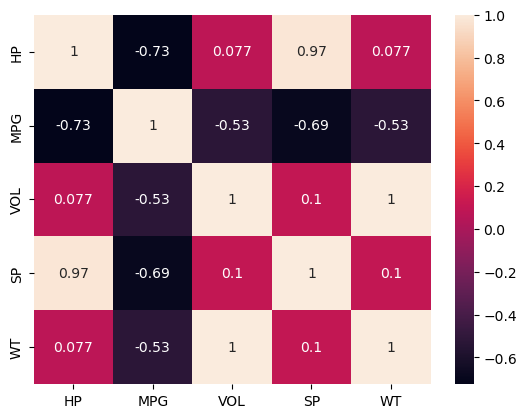

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data.corr(),annot=True)
plt.show()

In [6]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

# HP vs MPG

In [7]:
X=data[["HP"]]
Y=data['MPG']

lr.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
print(lr.coef_,lr.intercept_)

[-0.11592088] 48.039201646103045


In [9]:
lr.score(X,Y)

0.5256806086282022

# HP +SP vs MPG

In [10]:
X=data[["HP","SP"]]
Y=data['MPG']

lr.fit(X,Y)

print(lr.coef_,lr.intercept_)
lr.score(X,Y)

[-0.17308756  0.23641252] 26.020879737672107


0.532639171285165

# HP+SP+WT vs. MPG

In [11]:
X=data[["HP","SP","WT"]]
Y=data['MPG']

lr.fit(X,Y)

print(lr.coef_,lr.intercept_)
lr.score(X,Y)

[-0.20850232  0.40775263 -0.59941272] 28.784808215317597


0.769482813998346

# HP+SP+WT+VOL vs MPG

In [12]:
X=data[["HP","SP","WT","VOL"]]
Y=data['MPG']

lr.fit(X,Y)

print(lr.coef_,lr.intercept_)
lr.score(X,Y)

[-0.20544372  0.39562692  0.40057409 -0.33605084] 30.67733585215178


0.7705372737359844

# Multicolinearity

In [13]:
#Observation: High correlation between SP and Hp as well as Vol and Wt

In [14]:
#VIF: Variance Inflation Factor

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

linear=LinearRegression()

X=data[["SP","VOL","WT"]]
Y=data['HP']

model=linear.fit(X,Y)
r2_hp=r2_score(Y,linear.predict(X))

VIF_HP=1/(1-r2_hp)
VIF_HP

19.92658897499852

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

linear=LinearRegression()

X=data[["HP","VOL","WT"]]
Y=data['SP']

model=linear.fit(X,Y)
r2_sp=r2_score(Y,linear.predict(X))

VIF_SP=1/(1-r2_sp)
VIF_SP

20.00763878305008

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

linear=LinearRegression()

X=data[["SP","VOL","HP"]]
Y=data['WT']

model=linear.fit(X,Y)
r2_wt=r2_score(Y,linear.predict(X))

VIF_WT=1/(1-r2_wt)
VIF_WT

639.5338175572624

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

linear=LinearRegression()

X=data[["SP","WT","HP"]]
Y=data['VOL']

model=linear.fit(X,Y)
r2_vol=r2_score(Y,linear.predict(X))

VIF_VOL=1/(1-r2_vol)
VIF_VOL

638.8060836592878

In [19]:
df_1=pd.DataFrame([VIF_HP,VIF_SP,VIF_WT,VIF_VOL],index=["VIF_HP","VIF_SP","VIF_WT","VIF_VOL"]).sort_values(by=0)
df_1

,0
VIF_HP,19.926589
VIF_SP,20.007639
VIF_VOL,638.806084
VIF_WT,639.533818


# Final Model

In [17]:
X=data[["HP","SP","VOL"]]
Y=data['MPG']

linear_reg=LinearRegression()

linear_reg.fit(X,Y)

r2_score(Y,linear_reg.predict(X))

0.770368341321302

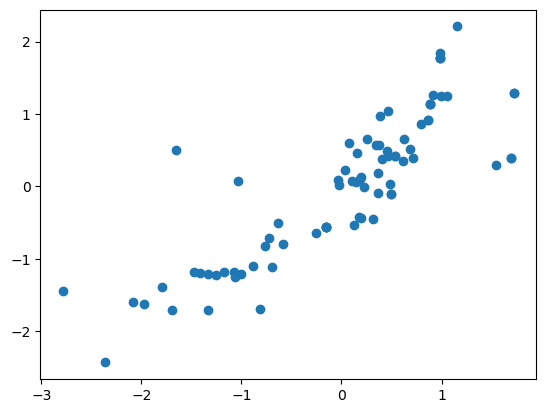

In [18]:
#Plot for Homoscedasticity
from sklearn.preprocessing import scale

Y_pred=scale(linear_reg.predict(X))
resid=scale(Y-Y_pred)

plt.scatter(Y_pred,resid)
plt.show()

In [19]:
linear_reg.coef_,linear_reg.intercept_

(array([-0.20670477,  0.40065935, -0.2016508 ]),
 np.float64(29.923389102475706))

In [21]:
#Test case
df=pd.DataFrame({"HP":43,"SP":107,"VOL":90},index=[0])
df

,HP,SP,VOL
0,43,107,90


In [22]:
linear_reg.predict(df)

array([45.75706173])